# LLM Fine Tuning · Lesson 8 · Reinforcement learning with a verifier (GRPO)

The task is the course's task: a question about a table in, one SQLite query out. Lessons 4 and 5 taught it by
imitation: show the model the right query, push its probability up. This lab teaches it by trial and score. The model
writes several queries for the same question, a **program** runs each one and scores it, and the model is pushed towards
the attempts that beat their own group. That is GRPO (group relative policy optimisation), and the program is the
verifier.

Six questions are asked, each answered by a measurement:

1. **Can a program score a SQL query, and can the scorer be trusted?** A small database is built for every question,
   the query is run, and its result is compared with the gold query's result. The scorer is then attacked with
   deliberately wrong queries to see which ones it wrongly accepts.
2. **Where does RL start from?** Zero-shot, then a short supervised warm start (lesson 4's recipe on fewer examples),
   all scored on the same 500 test questions as lessons 3 to 5, now by execution as well as exact match.
3. **What does a tempting reward teach?** A reward that gives partial credit for overlapping with the gold result is
   run first. It is a reward-hacking experiment: the reward and the true score are logged side by side.
4. **What does the strict reward teach?** The same run with a reward of 1 for the right result and 0 otherwise, with
   the reward mean and spread, the share of groups that teach nothing, the completion length and the KL logged per step.
5. **Did it help, and where?** All four systems side by side, plus which questions changed from wrong to right and back.
6. **What do we keep?** The adapter.

**Run it:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all. The estimate is about 50 minutes on a T4,
and it is an estimate: about 5 minutes of set-up, 2 of baseline, 6 of warm start, 12 on the reward-hacking run, 22 on
the strict run and 5 of scoring. Every size is one constant in the second code cell, so it can be scaled down.
The lesson that explains every result is at [docs.recohut.com](https://docs.recohut.com/courses/llm-fine-tuning/3-beyond-sft/08-grpo).

## 0. Install, load and rebuild the lesson 3 splits

In [1]:
# Pinned versions, so the code matches the lesson it was written for.
%pip install -q transformers==4.51.3 peft==0.15.2 accelerate==1.6.0 trl==0.19.1 datasets==3.6.0

pip may report dependency conflicts with packages Colab preinstalls, such as `gradio`. This lab does not use them,
so the warning can be ignored.

In [2]:
import gc
import json
import os
import random
import re
import sqlite3
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import torch
import transformers
import trl
from datasets import Dataset
from peft import LoraConfig, PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer, TrainerCallback, set_seed
from trl import GRPOConfig, GRPOTrainer, SFTConfig, SFTTrainer

%config InlineBackend.figure_formats = ['svg']
assert torch.cuda.is_available(), "Choose Runtime -> Change runtime type -> T4 GPU."

SEED = 42
set_seed(SEED)
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
DEVICE = "cuda"
DTYPE = torch.float16          # a T4 has no bfloat16 (lesson 2)
GB = 1e9

# The size knobs. Everything that costs time is here.
N_TEST = 500                   # held-out questions every system is scored on (the same 500 as lessons 3 to 5)
N_SFT = 2000                   # warm-start examples: a quarter of lesson 4's run, so that RL has room to improve it
PROMPTS_PER_STEP = 8           # different questions in one RL step
NUM_GEN = 8                    # answers sampled per question: the group size G
MICRO_BATCH, ACCUM = 16, 4     # 16 x 4 = 64 answers per step = PROMPTS_PER_STEP x NUM_GEN
MAX_COMPLETION = 64            # tokens an answer may take; 99.6% of gold answers are shorter (measured on 3,000 rows)
N_STEPS_HACK = 50              # RL steps with the tempting reward
N_STEPS = 100                  # RL steps with the strict reward
LR_RL = 2e-5                   # LoRA learning rate for RL
BETA = 0.04                    # KL weight, the value used for DeepSeekMath
assert MICRO_BATCH * ACCUM == PROMPTS_PER_STEP * NUM_GEN
print("transformers", transformers.__version__, "| trl", trl.__version__, "| peft", peft.__version__)
print("GPU:", torch.cuda.get_device_name(0))

transformers 4.51.3 | trl 0.19.1 | peft 0.15.2
GPU: Tesla T4


The data is rebuilt here with the same code and the same seed as lesson 3, so this lab runs on its own: drop gold
queries that fail in SQLite, drop exact duplicates, then split **by table** (5% test, 5% validation, the rest
training). The counts should match lesson 3: 69,170 training examples.

In [3]:
# Pinned to the same commit of the dataset as lesson 3 (b-mc2/sql-create-context, CC BY 4.0).
URL = ("https://huggingface.co/datasets/b-mc2/sql-create-context/resolve/"
       "9d80a6a118b838d9defc3798d659a54a2ac2ff37/sql_create_context_v4.json")
data = pd.DataFrame(json.load(urllib.request.urlopen(URL)))


def runs(context, sql):
    """Return None if the query runs against the (empty) schema, or the SQLite error message."""
    con = sqlite3.connect(":memory:")
    try:
        for statement in context.split(";"):
            if statement.strip():
                con.execute(statement)
        con.execute(sql)
        return None
    except sqlite3.Error as e:
        return str(e)
    finally:
        con.close()


data["error"] = [runs(c, a) for c, a in zip(data["context"], data["answer"])]

# A split group is one named table. WikiSQL's re-used names (table_name_N) are groups of one.
table = data["context"].str.extract(r"CREATE TABLE (\w+)")[0].fillna("")
named = ~table.str.fullmatch(r"table_name_\d+")
data["group"] = np.where(named, table, "row" + data.index.astype(str))

clean = data[data["error"].isna()].drop_duplicates(["question", "context", "answer"]).reset_index(drop=True)
uniq = np.random.default_rng(SEED).permutation(clean["group"].unique())
n = len(uniq)
split_of = {u: ("test" if i < 0.05 * n else "validation" if i < 0.10 * n else "train") for i, u in enumerate(uniq)}
clean["split"] = clean["group"].map(split_of)
print(clean["split"].value_counts().to_string())

SYSTEM = "You write SQLite queries. Answer with one SQL query and nothing else."


def messages(r):
    """One example in conversational prompt-completion form."""
    return {
        "prompt": [{"role": "system", "content": SYSTEM},
                   {"role": "user", "content": f"Schema:\n{r['context']}\n\nQuestion: {r['question']}"}],
        "completion": [{"role": "assistant", "content": r["answer"]}],
    }


rows = {s: clean[clean["split"] == s].to_dict("records") for s in ["train", "validation", "test"]}
assert len(rows["train"]) == 69170 and len(rows["validation"]) == 3817 and len(rows["test"]) == 3923

split
train         69170
test           3923
validation     3817


## 1. Can a program score a SQL query, and can the scorer be trusted?

Lessons 3 to 5 used two scores. **Runs** asks whether SQLite accepts the query; it does not look at the answer.
**Exact** compares the text with the gold query after normalising white space and case, so a correct query written
another way is a miss. Neither is what a user wants: the right *result*. RL needs a score a program can compute for
thousands of samples, so this section builds the third kind, **execution accuracy**.

For every question a small SQLite database is built from its `CREATE TABLE` statement. The rows are made from the schema
and from the literals in the gold query: two rows that satisfy every condition, one row per condition that breaks only
that condition, and a few random rows. The gold query and the model's query run on the same database, and the results
are compared as multisets of rows (as a list when the gold query has `ORDER BY`). The model never sees the database.

Three rules matter more than they look.

- **Questions whose gold result is empty are left out of training and of the execution score.** Otherwise any query that
  also returns nothing would be "correct". Arctic-Text2SQL-R1 (Snowflake) filters its training data the same way.
- **The model's SQL is run, so it is run safely.** An authoriser allows reads only (a `DROP`, `INSERT` or `ATTACH` is
  refused), and a progress handler stops a query that runs too long.
- **A scorer is a piece of software with bugs.** The last cell of this section attacks it.

In [4]:
# The environment: a small populated database per question, and a program that scores a query against the gold query.
# (Each rule is explained in the text above this cell.)
COMPARISON = re.compile(r"(?:\w+\.)?(\w+)\s*(>=|<=|!=|<>|=|>|<|LIKE)\s*(\"[^\"]*\"|'[^']*'|-?\d+(?:\.\d+)?)", re.I)


def literal_value(token):
    if token[0] in "\"'":
        return token[1:-1]
    return float(token) if "." in token else int(token)


def pair_for(op, v):
    """(a value that satisfies `column op v`, a value that breaks it)."""
    op = op.upper()
    if isinstance(v, str):
        core = v.strip("%")
        if op == "LIKE":
            return "a" + core + "b", "zz" + core[::-1] + "zz"
        if op == "=":
            return v, v + " (other)"
        if op in ("!=", "<>"):
            return v + " (other)", v
        return (v + "z", "0") if op in (">", ">=") else ("0", v + "z")
    if op == "=":
        return v, v + 1
    if op in ("!=", "<>", ">"):
        return v + 1, v
    if op == ">=":
        return v, v - 1
    if op == "<":
        return v - 1, v
    return v, v + 1                                              # <=


def build_db(context, gold, seed, n_noise=4):
    """Statements that create and fill a small database for one question.

    Rows come from the schema and from the literals in the gold query: two rows that satisfy every condition, one row
    per condition that breaks only that condition, and a few random rows. The model never sees this database.
    """
    rng = random.Random(seed)
    statements = [s.strip() for s in context.split(";") if s.strip()]
    con = sqlite3.connect(":memory:")
    for s in statements:
        con.execute(s)
    tables = [r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type = 'table'")]
    conditions = [(c.lower(), op, literal_value(t)) for c, op, t in COMPARISON.findall(gold)]
    out = list(statements)
    for t in tables:
        cols = [(r[1].lower(), (r[2] or "").upper()) for r in con.execute(f"PRAGMA table_info({t})")]
        mine = [(c, op, v) for c, op, v in conditions if c in {n for n, _ in cols}]

        def filler(name, ty):
            if any(k in ty for k in ("INT", "REAL", "NUM", "FLOAT", "DOUBLE")):
                return rng.randint(1, 6) if name.endswith("id") else rng.randint(1, 99)   # small ids, so joins can match
            return f"{name}_{rng.randint(0, 4)}"

        def row(break_i=None):
            r = {n: filler(n, ty) for n, ty in cols}
            for i, (c, op, v) in enumerate(mine):
                good, bad = pair_for(op, v)
                r[c] = bad if i == break_i else good
            return r

        rows = [row(), row()] + [row(i) for i in range(len(mine))]
        rows += [{n: filler(n, ty) for n, ty in cols} for _ in range(n_noise)]
        rng.shuffle(rows)
        for r in rows:
            vals = ", ".join("'" + v.replace("'", "''") + "'" if isinstance(v, str) else repr(v) for v in (r[n] for n, _ in cols))
            out.append(f"INSERT INTO {t} VALUES ({vals})")
    con.close()
    return out


READ_ONLY = {sqlite3.SQLITE_SELECT, sqlite3.SQLITE_READ, sqlite3.SQLITE_FUNCTION, sqlite3.SQLITE_RECURSIVE}


def execute(setup, sql, max_calls=200):
    """Run one query on a fresh copy of the database. Returns (rows, error). Read-only, and stopped if it runs too long."""
    con = sqlite3.connect(":memory:")
    try:
        for s in setup:
            con.execute(s)
        con.set_authorizer(lambda action, *a: sqlite3.SQLITE_OK if action in READ_ONLY else sqlite3.SQLITE_DENY)
        calls = [0]

        def too_long():
            calls[0] += 1
            return 1 if calls[0] > max_calls else 0              # called every 1,000 SQLite VM instructions

        con.set_progress_handler(too_long, 1000)
        rows = [tuple(round(v, 6) if isinstance(v, float) else v for v in r) for r in con.execute(sql).fetchmany(1000)]
        return rows, None
    except Exception as e:                                       # SQL errors, but also e.g. two statements in one string
        return None, str(e)
    finally:
        con.close()


def cells(rows):
    return {str(v) for r in rows for v in r}


def same_result(a, b, ordered):
    key = lambda r: tuple((type(x).__name__, str(x)) for x in r)
    return [key(r) for r in a] == [key(r) for r in b] if ordered else sorted(map(key, a)) == sorted(map(key, b))


def judge(setup, gold, sql):
    """Everything a program can read off one generated query, against the gold query on the same database."""
    gold_rows, _ = execute(setup, gold)
    rows, error = execute(setup, sql) if sql.strip() else (None, "empty answer")
    out = {"runs": error is None, "nonempty": bool(rows), "strict": 0.0, "overlap": 0.0}
    if error is None:
        out["strict"] = float(same_result(rows, gold_rows, " order by " in gold.lower()))
        want = cells(gold_rows)
        out["overlap"] = len(want & cells(rows)) / len(want) if want else 0.0
    return out

In [5]:
def clean_sql(text):
    """Strip white space and a Markdown code fence, if the model wrote one."""
    text = text.strip()
    return re.sub(r"^```(?:sql)?\s*|\s*```$", "", text, flags=re.I).strip()


def normalise(sql):
    sql = re.sub(r"\s+", " ", sql.strip().lower()).strip()
    return sql.rstrip(";").strip().replace('"', "'")


# The same 500 test questions as lessons 3 to 5 (same seed, same call).
test = random.Random(SEED).sample(rows["test"], N_TEST)
test_setup = [build_db(r["context"], r["answer"], seed=i) for i, r in enumerate(test)]
test_info = np.array([bool(execute(s, r["answer"])[0]) for s, r in zip(test_setup, test)])   # gold result not empty
print(f"test questions whose gold query returns rows on the database: {test_info.sum()} of {len(test)}")

# The scorer must give the gold query full marks, always.
for s, r in zip(test_setup, test):
    j = judge(s, r["answer"], r["answer"])
    assert j["runs"] and j["strict"] == 1.0
print("gold query scores 1.0 on all", len(test), "databases")

# A look at one question and its database.
k = next(i for i, r in enumerate(test) if test_info[i] and " WHERE " in r["answer"])
print("\nquestion:", test[k]["question"])
print("gold    :", test[k]["answer"])
print("database:", *[s for s in test_setup[k] if s.startswith("INSERT")][:5], sep="\n  ")
print("gold result:", execute(test_setup[k], test[k]["answer"])[0])

test questions whose gold query returns rows on the database: 483 of 500
gold query scores 1.0 on all 500 databases

question: What is Type, when Works Number is 75823?
gold    : SELECT type FROM table_name_16 WHERE works_number = "75823"
database:
  INSERT INTO table_name_16 VALUES ('type_4', 'works_number_1')
  INSERT INTO table_name_16 VALUES ('type_3', 'works_number_2')
  INSERT INTO table_name_16 VALUES ('type_3', 'works_number_2')
  INSERT INTO table_name_16 VALUES ('type_4', 'works_number_1')
  INSERT INTO table_name_16 VALUES ('type_3', '75823')
gold result: [('type_3',), ('type_0',)]


In [6]:
def mutants(gold):
    """Plausible wrong answers: the gold query broken in one way."""
    out = {"SELECT 1": "SELECT 1",
           "SELECT * instead of the columns": re.sub(r"^SELECT\s+.*?\s+FROM", "SELECT * FROM", gold, count=1, flags=re.I)}
    if re.search(r"\bWHERE\b", gold, re.I):
        out["drop the WHERE clause"] = re.sub(r"\s+WHERE\s+.*?(?=\s+(?:GROUP|ORDER|LIMIT|HAVING)\b|$)", "", gold, flags=re.I)
    if "=" in gold:
        out["flip the first ="] = gold.replace("=", "!=", 1)
    if "MAX(" in gold:
        out["MAX to MIN"] = gold.replace("MAX(", "MIN(")
    if "COUNT(" in gold:
        out["COUNT to SUM"] = gold.replace("COUNT(", "SUM(")
    return out


# Attack the scorer on the test questions with a non-empty gold result.
attack = {}
for s, r, info in zip(test_setup, test, test_info):
    if not info:
        continue
    for name, sql in mutants(r["answer"]).items():
        if sql != r["answer"]:
            attack.setdefault(name, []).append(judge(s, r["answer"], sql))
table_attack = pd.DataFrame({
    name: {"mutants": len(js), "runs, %": 100 * np.mean([j["runs"] for j in js]),
           "scored correct by the strict reward, %": 100 * np.mean([j["strict"] for j in js]),
           "mean overlap reward": np.mean([j["overlap"] for j in js])} for name, js in attack.items()}).T.round(2)
table_attack["mutants"] = table_attack["mutants"].astype(int)
print(table_attack.to_string())

                                 mutants  runs, %  scored correct by the strict reward, %  mean overlap reward
SELECT 1                             483   100.00                                    0.21                 0.01
SELECT * instead of the columns      482   100.00                                    1.04                 0.83
drop the WHERE clause                461    99.78                                    2.60                 0.78
flip the first =                     450    99.78                                    0.89                 0.44
MAX to MIN                            24   100.00                                    0.00                 0.11
COUNT to SUM                          48    75.00                                    0.00                 0.00


The strict reward is rarely fooled: a mutant scored correct is either a query that really returns the same result on
this database (a `WHERE` that removes nothing) or a coincidence. These are false positives, and each is a small hole an
RL run could find. The last column is a second reward, **overlap**, introduced in section 3. Read it now as the answer
to a question: how much partial credit does each wrong query earn?

## 2. Where does RL start from?

RL can only reinforce what the model already sometimes does. If it never writes a correct query, every group scores zero
and nothing is learned. So RL starts from a model that is already reasonable: here, the base model plus a short
supervised warm start. DeepSeek-R1 does the same at a larger scale (a "cold start" of supervised examples before RL).

The warm start is lesson 4's recipe on fewer examples: LoRA rank 16 on every linear layer, loss on the answer only.
The adapter is then **merged into the base weights and saved**. That matters for GRPO in TRL: with a LoRA adapter the
reference model for the KL penalty is "the model with the adapter switched off". If the warm-start adapter were left
on, the reference would be the untrained base model, not the model RL starts from. After the merge a *new* adapter is
trained on top, and "adapter off" is the warm-start model.

First, the evaluation function used for every system. It generates greedy answers for the 500 test questions and
scores each one in several ways.

In [7]:
def free_gpu():
    gc.collect()
    torch.cuda.empty_cache()


tok = AutoTokenizer.from_pretrained(MODEL_ID, padding_side="left")


@torch.inference_mode()
def generate(model, tok, prompts, batch=16, max_new_tokens=128):
    """Greedy answers for a list of chat prompts, batched with left padding. Returns (answers, ms per example)."""
    model.generation_config.update(temperature=None, top_p=None, top_k=None)

    def run(chunk, n_new):
        texts = [tok.apply_chat_template(p, tokenize=False, add_generation_prompt=True) for p in chunk]
        enc = tok(texts, return_tensors="pt", padding=True).to(DEVICE)
        out = model.generate(**enc, max_new_tokens=n_new, do_sample=False, pad_token_id=tok.pad_token_id)
        return tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)

    run(prompts[:2], 4)                        # warm-up, so start-up cost is not timed
    answers, start = [], time.perf_counter()
    for i in range(0, len(prompts), batch):
        answers += run(prompts[i:i + batch], max_new_tokens)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    return answers, 1000 * (time.perf_counter() - start) / len(prompts)


def flags(gold, sql):
    """Two behaviours worth watching: writing SELECT *, and leaving out a WHERE the gold query has."""
    star = bool(re.match(r"select\s+\*", sql, re.I))
    dropped = bool(re.search(r"\bwhere\b", gold, re.I)) and not re.search(r"\bwhere\b", sql, re.I)
    return star, dropped


results, scored = {}, {}


def evaluate(name, model):
    """Greedy answers for the 500 test questions, scored by runs, exact match, execution (strict) and overlap."""
    answers, ms = generate(model, tok, [messages(r)["prompt"] for r in test])
    out = []
    for s, r, a in zip(test_setup, test, answers):
        sql = clean_sql(a)
        j = judge(s, r["answer"], sql)
        star, dropped = flags(r["answer"], sql)
        out.append({"sql": sql, "runs": j["runs"], "exact": normalise(sql) == normalise(r["answer"]), "strict": j["strict"],
                    "overlap": j["overlap"], "star": star, "where dropped": dropped,
                    "has where": bool(re.search(r"\bwhere\b", r["answer"], re.I)), "tokens": len(tok(sql)["input_ids"])})
    d = scored[name] = pd.DataFrame(out)
    n_info, n_where = int(test_info.sum()), int(d["has where"].sum())
    results[name] = {
        "runs": d["runs"].mean(), "exact": d["exact"].mean(),
        "execution": d["strict"][test_info].mean(), "overlap": d["overlap"][test_info].mean(),
        "SELECT *": d["star"].mean(), "WHERE dropped": (d["where dropped"] & d["has where"]).sum() / n_where,
        "tokens": d["tokens"].mean(), "ms per example": ms}
    r = results[name]
    print(f"{name:26s} runs {r['runs']:.1%}  exact {r['exact']:.1%}  execution {r['execution']:.1%}  "
          f"overlap {r['overlap']:.3f}  SELECT * {r['SELECT *']:.1%}  WHERE dropped {r['WHERE dropped']:.1%}")


base = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map={"": DEVICE}).eval()
evaluate("base, zero-shot", base)
del base
free_gpu()

base, zero-shot            runs 96.2%  exact 58.4%  execution 60.9%  overlap 0.641  SELECT * 0.2%  WHERE dropped 0.0%


Now the warm start. It uses the first `N_SFT` examples of one shared random sample of the training split, and the RL
questions come from the rest of that sample, so RL sees questions the warm start did not.

In [8]:
POOL = PROMPTS_PER_STEP * N_STEPS + 300
train_sample = random.Random(SEED).sample(rows["train"], N_SFT + POOL)
sft_rows, pool_rows = train_sample[:N_SFT], train_sample[N_SFT:]
sft_ds = Dataset.from_list([messages(r) for r in sft_rows])

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map={"": DEVICE})
model.config.use_cache = False       # incompatible with gradient checkpointing
sft_config = SFTConfig(
    output_dir="sft-out", per_device_train_batch_size=8, gradient_accumulation_steps=2,
    num_train_epochs=1, learning_rate=2e-4, lr_scheduler_type="cosine", warmup_ratio=0.03,
    fp16=True, bf16=False, gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    max_length=256, completion_only_loss=True, logging_steps=25, save_strategy="no", report_to="none", seed=SEED)
sft = SFTTrainer(model=model, args=sft_config, train_dataset=sft_ds, processing_class=tok,
                 peft_config=LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear",
                                        task_type="CAUSAL_LM"))
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
sft.train()
sft_minutes = (time.perf_counter() - start) / 60
sft_peak = torch.cuda.max_memory_allocated() / GB
print(f"\nwarm start: {N_SFT:,} examples, {sft_minutes:.1f} minutes, peak {sft_peak:.2f} GB")

merged = sft.model.merge_and_unload()          # the adapter becomes part of the weights
merged.config.use_cache = True
merged.save_pretrained("sft-merged")
tok.save_pretrained("sft-merged")
del sft, merged, model
free_gpu()

Step,Training Loss
25,0.130400
50,0.056300
75,0.049100
100,0.037600
125,0.047000



warm start: 2,000 examples, 3.6 minutes, peak 6.61 GB


In [9]:
# Score what RL will start from, loaded back from disk.
start_model = AutoModelForCausalLM.from_pretrained("sft-merged", torch_dtype=DTYPE, device_map={"": DEVICE}).eval()
evaluate("warm start (SFT)", start_model)
del start_model
free_gpu()

warm start (SFT)           runs 98.8%  exact 67.6%  execution 79.5%  overlap 0.806  SELECT * 0.2%  WHERE dropped 0.0%


## 3. What does a tempting reward teach?

Two rewards, both computed by the program of section 1.

- **strict:** 1 if the query's result equals the gold result, otherwise 0. A query that does not run gets 0 too. There is
  no credit for "runs": the warm-start model already runs almost every time, so a credit for it would carry no
  information and only give a policy something to farm. Arctic-Text2SQL-R1 gives 0.1 for a query that executes; its
  authors report that richer partial credit invited hacking.
- **overlap:** the share of the gold result's distinct cell values that appear anywhere in the model's result. This is
  the partial credit a designer reaches for first ("it was nearly right, give it something"), and precision/recall
  rewards of this kind appear in published text-to-SQL RL work.

The overlap reward has a hole. A query that returns *everything* contains every cell the gold query returns. Before any
training, the cell below scores a policy that does not read the question at all (always `SELECT * FROM` the first
table) under both rewards, and sets it beside the warm-start model.

In [10]:
trivial = []
for s, r, info in zip(test_setup, test, test_info):
    if info:
        sql = "SELECT * FROM " + re.search(r"CREATE TABLE (\w+)", r["context"]).group(1)
        trivial.append(judge(s, r["answer"], sql))
probe = pd.DataFrame({
    "a policy that never reads the question": {"strict reward": np.mean([j["strict"] for j in trivial]),
                                               "overlap reward": np.mean([j["overlap"] for j in trivial])},
    "warm-start model (greedy)": {"strict reward": results["warm start (SFT)"]["execution"],
                                  "overlap reward": results["warm start (SFT)"]["overlap"]}}).T.round(3)
print(f"{len(trivial)} test questions with a non-empty gold result\n")
print(probe.to_string())

483 test questions with a non-empty gold result

                                        strict reward  overlap reward
a policy that never reads the question          0.000           0.831
warm-start model (greedy)                       0.795           0.806


The two rewards disagree about the same two policies. This is Goodhart's law in four lines: a measure that is a good
guide while nobody optimises it stops being one when something does. What follows measures whether RL finds the hole.

Now the machinery. Per question the trainer samples `NUM_GEN` answers and the reward scores each. The advantage of
answer $i$ is how far it is above its own group, in group standard deviations:

$$\hat A_i=\frac{r_i-\operatorname{mean}(r_1..r_G)}{\operatorname{std}(r_1..r_G)+10^{-4}}$$

(TRL 0.19.1 adds $10^{-4}$ to the standard deviation, `grpo_trainer.py`.) Every token of answer $i$ is pushed by the same
$\hat A_i$. There is no value model: the group mean is the baseline. The objective TRL maximises per token is

$$\min\!\big(\rho\,\hat A,\ \operatorname{clip}(\rho,1-\varepsilon,1+\varepsilon)\,\hat A\big)-\beta\,D_{KL},\qquad
\rho=\frac{\pi_\theta(o_t\mid q,o_{<t})}{\pi_{\theta_{old}}(o_t\mid q,o_{<t})}$$

with $D_{KL}=\frac{\pi_{ref}}{\pi_\theta}-\log\frac{\pi_{ref}}{\pi_\theta}-1$ per token. Two consequences are checked below.
A group whose answers all score the same has zero advantage and teaches nothing. And because this lab takes one update
per batch of samples, $\pi_\theta=\pi_{\theta_{old}}$ at the moment of the update, so $\rho=1$ and the clip never
fires; the logged clip ratio should be zero.

In [11]:
# Arithmetic, not a measurement: the advantage of a correct and of a wrong answer in a group of NUM_GEN with a 0/1 reward.
rows_adv = []
for k in range(NUM_GEN + 1):
    r = np.array([1.0] * k + [0.0] * (NUM_GEN - k))
    a = (r - r.mean()) / (r.std(ddof=1) + 1e-4)       # std with ddof=1, as torch.std does in TRL
    rows_adv.append({"correct in the group": k, "advantage of a correct answer": a[0] if k else np.nan,
                     "advantage of a wrong answer": a[-1] if k < NUM_GEN else np.nan})
print(pd.DataFrame(rows_adv).round(2).to_string(index=False))

 correct in the group  advantage of a correct answer  advantage of a wrong answer
                    0                            NaN                         0.00
                    1                           2.47                        -0.35
                    2                           1.62                        -0.54
                    3                           1.21                        -0.72
                    4                           0.94                        -0.94
                    5                           0.72                        -1.21
                    6                           0.54                        -1.62
                    7                           0.35                        -2.47
                    8                           0.00                          NaN


### The training run

Everything below is one function, so the two runs differ only in the reward. The settings and why:

- **LoRA again, new adapter, no dropout.** TRL generates the samples with the model in training mode, so dropout would
  make the sampled answers differ from the ones whose probabilities are trained.
- **No gradient checkpointing.** In training mode, checkpointing switches off the key-value cache, which makes sampling
  far slower (transformers 4.51.3, `modeling_qwen2.py`). The batch is small enough to fit without it.
- **Temperature 1, no top-k or top-p.** The samples must be draws from the policy being trained.
- **One update per batch of samples** (`num_iterations=1`), group size `NUM_GEN`, `PROMPTS_PER_STEP` questions per step.
- **`loss_type="bnpo"`, `scale_rewards=True`:** TRL 0.19.1's defaults, written out. Dr. GRPO argues for neither the
  per-answer length normalisation nor the division by the standard deviation; the lesson says why.
- **fp16 on a T4.** The base model is fp16 and the adapter is float32, as in lesson 4.

Each run logs, per step: the mean reward, the spread of rewards inside groups, the share of groups with zero spread,
the mean completion length and the KL to the warm-start model. A side channel records the *other* reward and the
two behaviours from section 2 for every sampled answer, so a run can be judged by a score it was not trained on.

In [12]:
def make_reward(kind, log):
    """A TRL reward function. It trains on `kind` and records every score in `log` (one entry per RL step)."""
    def reward(prompts, completions, setup, gold, **kwargs):
        sqls = [clean_sql(c[0]["content"]) for c in completions]
        js = [judge(s, g, q) for s, g, q in zip(setup, gold, sqls)]
        fl = [flags(g, q) for g, q in zip(gold, sqls)]
        log.append({"strict": np.mean([j["strict"] for j in js]), "overlap": np.mean([j["overlap"] for j in js]),
                    "runs": np.mean([j["runs"] for j in js]), "SELECT *": np.mean([f[0] for f in fl]),
                    "WHERE dropped": np.mean([f[1] for f in fl])})
        return [j[kind] for j in js]
    reward.__name__ = f"{kind}_reward"
    return reward


# RL questions: from the pool the warm start did not see, with a non-empty gold result on their database.
rl_items = []
for i, r in enumerate(pool_rows):
    setup = build_db(r["context"], r["answer"], seed=100_000 + i)
    if execute(setup, r["answer"])[0]:
        rl_items.append({"prompt": messages(r)["prompt"], "setup": setup, "gold": r["answer"]})
print(f"{len(rl_items)} of {len(pool_rows)} pool questions have a non-empty gold result; "
      f"{PROMPTS_PER_STEP * N_STEPS} are needed for the longer run")
assert len(rl_items) >= PROMPTS_PER_STEP * N_STEPS


class Progress(TrainerCallback):
    """A short line every 10 steps instead of a log dictionary for every step."""
    def __init__(self):
        self.start = time.perf_counter()

    def on_log(self, args, state, control, logs=None, **kw):
        if logs and "reward" in logs and state.global_step % 10 == 0:
            print(f"step {state.global_step:3d}  reward {logs['reward']:.3f}  std in group {logs['reward_std']:.3f}  "
                  f"groups with no spread {logs['frac_reward_zero_std']:.0%}  length {logs['completions/mean_length']:.1f}  "
                  f"kl {logs.get('kl', float('nan')):.4f}  {time.perf_counter() - self.start:.0f} s")


runs_log, side_log, rl_stats = {}, {}, {}


def run_grpo(kind, steps):
    """Train a new LoRA adapter on the warm-start model with the reward `kind`. Saves it to ./grpo-<kind>."""
    free_gpu()
    model = AutoModelForCausalLM.from_pretrained("sft-merged", torch_dtype=DTYPE, device_map={"": DEVICE})
    log = []
    config = GRPOConfig(
        output_dir=f"grpo-{kind}-out", max_steps=steps,
        per_device_train_batch_size=MICRO_BATCH, gradient_accumulation_steps=ACCUM,   # 64 answers per step
        num_generations=NUM_GEN, max_prompt_length=160, max_completion_length=MAX_COMPLETION,
        temperature=1.0, beta=BETA, num_iterations=1, loss_type="bnpo", scale_rewards=True,
        learning_rate=LR_RL, lr_scheduler_type="constant_with_warmup", warmup_steps=5,
        fp16=True, bf16=False, use_vllm=False, logging_steps=1,
        save_strategy="no", report_to="none", seed=SEED)
    lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.0, target_modules="all-linear", task_type="CAUSAL_LM")
    trainer = GRPOTrainer(model=model, reward_funcs=make_reward(kind, log), args=config,
                          train_dataset=Dataset.from_list(rl_items[:PROMPTS_PER_STEP * steps]),
                          processing_class=tok, peft_config=lora, callbacks=[Progress()])
    n_trainable, n_all = trainer.model.get_nb_trainable_parameters()
    print(f"trainable parameters: {n_trainable:,} of {n_all:,}; reference model = the warm start (adapter switched off)")
    torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    trainer.train()
    secs = time.perf_counter() - start
    runs_log[kind] = pd.DataFrame([h for h in trainer.state.log_history if "reward" in h])
    side_log[kind] = pd.DataFrame(log)
    rl_stats[kind] = {"steps": steps, "minutes": secs / 60, "s per step": secs / steps,
                      "peak GB": torch.cuda.max_memory_allocated() / GB}
    print(f"\n{steps} steps in {secs / 60:.1f} minutes ({secs / steps:.1f} s per step), "
          f"peak GPU memory {rl_stats[kind]['peak GB']:.2f} GB")
    trainer.model.save_pretrained(f"grpo-{kind}")
    del trainer, model
    free_gpu()


def evaluate_adapter(name, kind):
    m = PeftModel.from_pretrained(
        AutoModelForCausalLM.from_pretrained("sft-merged", torch_dtype=DTYPE, device_map={"": DEVICE}), f"grpo-{kind}").eval()
    evaluate(name, m)
    del m
    free_gpu()

1069 of 1100 pool questions have a non-empty gold result; 800 are needed for the longer run


### Run 1: the tempting reward

The training signal here is the **overlap** reward. The strict score of every sampled answer is recorded but not used.
If the model learns what the reward pays for, the overlap reward rises while the strict score does not, and the
behaviours `SELECT *` and a dropped `WHERE` become more common.

In [13]:
run_grpo("overlap", N_STEPS_HACK)
evaluate_adapter("GRPO, overlap reward", "overlap")

trainable parameters: 18,464,768 of 1,562,179,072; reference model = the warm start (adapter switched off)


Step,Training Loss
1,0.006100
2,0.000600
3,0.000000
4,0.002400
5,0.000200
6,0.008700
7,0.000000
8,0.018400
9,0.000000
10,0.008400


step  10  reward 0.938  std in group 0.116  groups with no spread 75%  length 23.3  kl 0.0001  110 s


step  20  reward 1.000  std in group 0.000  groups with no spread 100%  length 25.0  kl 0.0006  219 s


step  30  reward 1.000  std in group 0.000  groups with no spread 100%  length 21.4  kl 0.0002  324 s


step  40  reward 0.422  std in group 0.102  groups with no spread 75%  length 28.9  kl 0.0071  432 s


step  50  reward 0.750  std in group 0.000  groups with no spread 100%  length 27.6  kl 0.0000  552 s



50 steps in 9.2 minutes (11.0 s per step), peak GPU memory 12.62 GB


GRPO, overlap reward       runs 98.6%  exact 68.8%  execution 81.0%  overlap 0.820  SELECT * 0.2%  WHERE dropped 0.0%


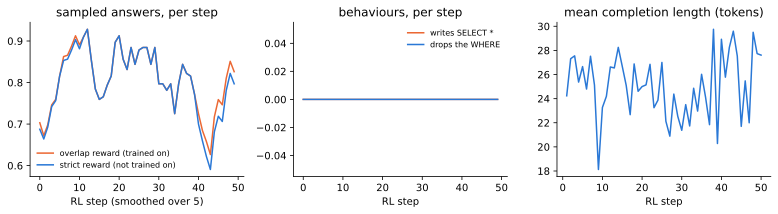

               first 10 steps  last 10 steps
strict                  0.830          0.739
overlap                 0.836          0.772
runs                    0.988          0.998
SELECT *                0.000          0.000
WHERE dropped           0.000          0.000


In [14]:
def smooth(x, w=5):
    return pd.Series(x).rolling(w, min_periods=1).mean().to_numpy()


s = side_log["overlap"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.1))
axes[0].plot(smooth(s["overlap"]), color="#eb6834", label="overlap reward (trained on)")
axes[0].plot(smooth(s["strict"]), color="#2a78d6", label="strict reward (not trained on)")
axes[0].set_title("sampled answers, per step")
axes[1].plot(smooth(s["SELECT *"]), color="#eb6834", label="writes SELECT *")
axes[1].plot(smooth(s["WHERE dropped"]), color="#2a78d6", label="drops the WHERE")
axes[1].set_title("behaviours, per step")
axes[2].plot(runs_log["overlap"]["step"], runs_log["overlap"]["completions/mean_length"], color="#2a78d6")
axes[2].set_title("mean completion length (tokens)")
for ax in axes:
    ax.set_xlabel("RL step (smoothed over 5)" if ax is axes[0] else "RL step")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
first, last = s.head(10).mean(), s.tail(10).mean()
print(pd.DataFrame({"first 10 steps": first, "last 10 steps": last}).round(3).to_string())

In [15]:
# What did the policy learn to write? Test questions where the overlap-trained model's answer differs from the warm start's.
a, b = scored["warm start (SFT)"], scored["GRPO, overlap reward"]
diff = np.where((a["sql"] != b["sql"]) & test_info)[0]
print(f"{len(diff)} of {int(test_info.sum())} questions got a different query\n")
for i in diff[:6]:
    print("question  :", test[i]["question"])
    print("gold      :", test[i]["answer"])
    print("warm start:", a.loc[i, "sql"], f"  (strict {a.loc[i, 'strict']:.0f}, overlap {a.loc[i, 'overlap']:.2f})")
    print("overlap RL:", b.loc[i, "sql"], f"  (strict {b.loc[i, 'strict']:.0f}, overlap {b.loc[i, 'overlap']:.2f})\n")

47 of 483 questions got a different query

question  : What Week 3 has a Week 4 of gina blair?
gold      : SELECT week_3 FROM table_name_95 WHERE week_4 = "gina blair"
warm start: SELECT COUNT(week_3) FROM table_name_95 WHERE week_4 = "gina blair"   (strict 0, overlap 0.00)
overlap RL: SELECT week_3 FROM table_name_95 WHERE week_4 = "gina blair"   (strict 1, overlap 1.00)

question  : Show all branch names with the number of members in each branch registered after 2015.
gold      : SELECT T2.name, COUNT(*) FROM membership_register_branch AS T1 JOIN branch AS T2 ON T1.branch_id = T2.branch_id WHERE T1.register_year > 2015 GROUP BY T2.branch_id
warm start: SELECT T1.name FROM branch AS T1 JOIN membership_register_branch AS T2 ON T1.branch_id = T2.branch_id WHERE T2.register_year > 2015   (strict 0, overlap 0.50)
overlap RL: SELECT b.name FROM branch AS b JOIN membership_register_branch AS mrb ON b.branch_id = mrb.branch_id WHERE mrb.register_year > 2015 GROUP BY b.name   (strict 0, overl

## 4. What does the strict reward teach?

The same run, from the same warm start with the same settings, with the strict reward. The overlap score and the two
behaviours are recorded again, this time as bystanders. This run is longer because it is the one whose result is kept.

In [16]:
run_grpo("strict", N_STEPS)
evaluate_adapter("GRPO, strict reward", "strict")

trainable parameters: 18,464,768 of 1,562,179,072; reference model = the warm start (adapter switched off)


Step,Training Loss
1,-0.005200
2,0.000100
3,0.000000
4,0.000000
5,-0.013000
6,-0.003900
7,-0.001100
8,0.004500
9,-0.000900
10,0.001800


step  10  reward 0.781  std in group 0.109  groups with no spread 75%  length 23.7  kl 0.0000  116 s


step  20  reward 0.891  std in group 0.044  groups with no spread 88%  length 23.0  kl 0.0001  226 s


step  30  reward 0.766  std in group 0.132  groups with no spread 75%  length 24.1  kl 0.0050  345 s


step  40  reward 0.875  std in group 0.134  groups with no spread 75%  length 21.5  kl 0.0002  455 s


... (4 outputs left out)

step  90  reward 0.641  std in group 0.044  groups with no spread 88%  length 28.8  kl 0.0073  989 s


step 100  reward 0.875  std in group 0.000  groups with no spread 100%  length 26.8  kl 0.0083  1099 s



100 steps in 18.3 minutes (11.0 s per step), peak GPU memory 13.73 GB


GRPO, strict reward        runs 99.0%  exact 68.4%  execution 80.7%  overlap 0.818  SELECT * 0.2%  WHERE dropped 0.0%


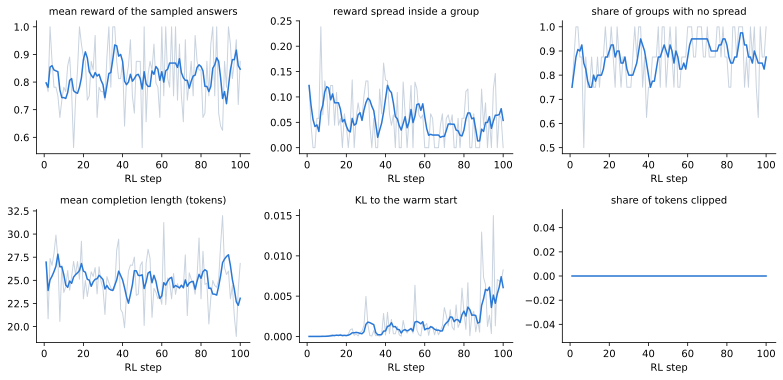

clip ratio, largest value over the run: 0.0
               first 10 steps  last 10 steps
strict                  0.794          0.845
overlap                 0.807          0.855
runs                    0.983          0.995
SELECT *                0.000          0.000
WHERE dropped           0.002          0.000


In [17]:
h = runs_log["strict"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.4))
panels = [("reward", "mean reward of the sampled answers"), ("reward_std", "reward spread inside a group"),
          ("frac_reward_zero_std", "share of groups with no spread"), ("completions/mean_length", "mean completion length (tokens)"),
          ("kl", "KL to the warm start"), ("clip_ratio/region_mean", "share of tokens clipped")]
for ax, (col, title) in zip(axes.ravel(), panels):
    ax.plot(h["step"], h[col], color="#c9d3df", lw=1)
    ax.plot(h["step"], smooth(h[col]), color="#2a78d6")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("RL step")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print("clip ratio, largest value over the run:", float(h["clip_ratio/region_mean"].max()))
s = side_log["strict"]
print(pd.DataFrame({"first 10 steps": s.head(10).mean(), "last 10 steps": s.tail(10).mean()}).round(3).to_string())

## 5. Did it help, and where?

Four systems on the same 500 questions, greedy decoding. **Execution** is the strict score on the questions whose gold
result is not empty. The ± column is the 95% interval, $1.96\sqrt{p(1-p)/n}$ with $n$ the number of those questions.
Differences smaller than the interval are not evidence.

In [18]:
n_info = int(test_info.sum())
table = pd.DataFrame(results).T
table["execution ±"] = 1.96 * np.sqrt(table["execution"] * (1 - table["execution"]) / n_info)
show = pd.DataFrame({
    "runs, %": 100 * table["runs"], "exact, %": 100 * table["exact"], "execution, %": 100 * table["execution"],
    "execution ±": 100 * table["execution ±"], "overlap reward": table["overlap"],
    "SELECT *, %": 100 * table["SELECT *"], "WHERE dropped, %": 100 * table["WHERE dropped"],
    "tokens": table["tokens"]}).round(1)
print(f"execution is scored on {n_info} of {N_TEST} questions\n")
print(show.to_string())
print()
print(pd.DataFrame(rl_stats).T.round(1).to_string())
print(f"warm start: {N_SFT:,} examples, {sft_minutes:.1f} minutes, peak {sft_peak:.1f} GB")

execution is scored on 483 of 500 questions

                      runs, %  exact, %  execution, %  execution ±  overlap reward  SELECT *, %  WHERE dropped, %  tokens
base, zero-shot          96.2      58.4          60.9          4.4             0.6          0.2               0.0    25.3
warm start (SFT)         98.8      67.6          79.5          3.6             0.8          0.2               0.0    24.8
GRPO, overlap reward     98.6      68.8          81.0          3.5             0.8          0.2               0.0    24.8
GRPO, strict reward      99.0      68.4          80.7          3.5             0.8          0.2               0.0    24.3

         steps  minutes  s per step  peak GB
overlap   50.0      9.2        11.0     12.6
strict   100.0     18.3        11.0     13.7
warm start: 2,000 examples, 3.6 minutes, peak 6.6 GB


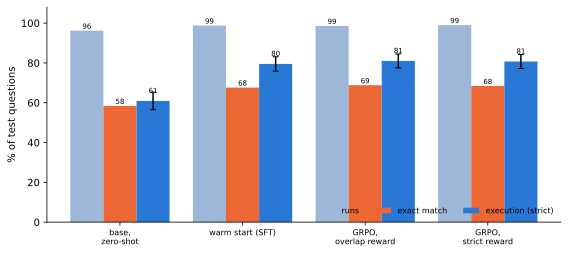

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(table))
w = 0.27
ax.bar(x - w, show["runs, %"], w, color="#9db7d8", label="runs")
ax.bar(x, show["exact, %"], w, color="#eb6834", label="exact match")
ax.bar(x + w, show["execution, %"], w, yerr=show["execution ±"], capsize=3, color="#2a78d6", label="execution (strict)")
for i, (a, b, c) in enumerate(zip(show["runs, %"], show["exact, %"], show["execution, %"])):
    ax.text(i - w, a + 1, f"{a:.0f}", ha="center", fontsize=7)
    ax.text(i, b + 1, f"{b:.0f}", ha="center", fontsize=7)
    ax.text(i + w, c + 4, f"{c:.0f}", ha="center", fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels([n.replace(", ", ",\n") for n in table.index], fontsize=8)
ax.set_ylabel("% of test questions")
ax.set_ylim(0, 108)
ax.legend(frameon=False, ncol=3, loc="lower right", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [20]:
# Which questions changed? Warm start against each RL run, on the strict score.
for name in ["GRPO, overlap reward", "GRPO, strict reward"]:
    before, after = scored["warm start (SFT)"]["strict"][test_info], scored[name]["strict"][test_info]
    gained, lost = int(((before == 0) & (after == 1)).sum()), int(((before == 1) & (after == 0)).sum())
    print(f"{name:24s} wrong -> right: {gained:3d}   right -> wrong: {lost:3d}   net {gained - lost:+d} of {n_info}")

# What is left? The strict-reward model's wrong answers, by what the program can see.
d = scored["GRPO, strict reward"][test_info]
print("\nstrict-reward model, questions with a non-empty gold result:")
print(f"  correct on execution            {int((d['strict'] == 1).sum())}")
print(f"  correct on execution, not exact {int(((d['strict'] == 1) & ~d['exact']).sum())}   (a different query, the same answer)")
print(f"  runs but wrong result           {int(((d['strict'] == 0) & d['runs']).sum())}")
print(f"  does not run                    {int((~d['runs']).sum())}")

GRPO, overlap reward     wrong -> right:  16   right -> wrong:   9   net +7 of 483
GRPO, strict reward      wrong -> right:  26   right -> wrong:  20   net +6 of 483

strict-reward model, questions with a non-empty gold result:
  correct on execution            390
  correct on execution, not exact 62   (a different query, the same answer)
  runs but wrong result           90
  does not run                    3


## 6. What do we keep?

Two adapters were saved, `./grpo-overlap` and `./grpo-strict`. Each is a LoRA adapter for the **warm-start model** in
`./sft-merged`, not for the original Qwen2.5-1.5B-Instruct: the base the adapter was trained on is part of the
artefact. In Colab, download the folders from the Files panel.

In [21]:
for folder in ["sft-merged", "grpo-strict", "grpo-overlap"]:
    size = sum(os.path.getsize(os.path.join(folder, f)) for f in os.listdir(folder)) / 1e6
    print(f"{folder:14s} {size:8.1f} MB   {sorted(os.listdir(folder))[:4]}")
print(json.load(open("grpo-strict/adapter_config.json"))["base_model_name_or_path"])

sft-merged       3103.3 MB   ['added_tokens.json', 'config.json', 'generation_config.json', 'merges.txt']
grpo-strict        73.9 MB   ['README.md', 'adapter_config.json', 'adapter_model.safetensors']
grpo-overlap       73.9 MB   ['README.md', 'adapter_config.json', 'adapter_model.safetensors']
sft-merged


## Read the result

- **The scorer comes first.** Section 1's attack says which wrong queries the reward accepts. Every false positive in a
  reward is a place RL can go.
- **Compare the two runs by the score they were not trained on.** The reward a run optimises always rises; whether the
  strict score and the behaviours moved with it is the evidence of hacking or of its absence.
- **Read the training curves for what they cannot show:** a group with no spread teaches nothing, a KL that grows
  without a matching gain is drift, a clip ratio of zero is expected with one update per batch.
- **Execution accuracy is not exact match.** The table separates "a different query, the same answer" from "the same
  text".
- **This is a small run:** `N_STEPS` steps on one GPU. The size knobs are in the second code cell.

The lesson explains each result and the companies that learned the same lessons:
[Reinforcement learning with a verifier (GRPO)](https://docs.recohut.com/courses/llm-fine-tuning/3-beyond-sft/08-grpo).